# Week 2 — Skincare Reviews: Environment Check

This cell imports the libraries used in this notebook and checks that Jupyter is running from the `skincare-ds` environment. `sys.executable` shows the Python interpreter path. Pandas is used for table data, NumPy for numerical operations, Matplotlib and Seaborn for charts, and the remaining packages support Hugging Face data access and notebook widgets.

**Expected:** the Python path should point to `...\envs\skincare-ds\python.exe` and the imports should complete without errors.

In [3]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import fsspec
import huggingface_hub
import ipywidgets as widgets

print("Python path:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Environment is ready!")
print("Jupyter widgets working!")

Python path: C:\Users\muppu\anaconda3\envs\skincare-ds\python.exe
Pandas: 3.0.6
NumPy: 2.5.4
Environment is ready!
Jupyter widgets working!


## 1. Load the Amazon Beauty Reviews sample

`dataset_path` stores the Hugging Face CSV location. `pd.read_csv()` reads the CSV into a Pandas DataFrame. The argument `nrows=10000` limits this exercise to the first 10,000 records so that we can inspect the data without loading the full file.

`df_raw` keeps the loaded sample as the original copy. `df = df_raw.copy()` creates a separate working copy that we can explore and clean without changing `df_raw`.

In [5]:
dataset_path = "hf://datasets/jhan21/amazon-beauty-reviews-dataset/amazon_beauty_reviews_dataset.csv"

df_raw = pd.read_csv(
    dataset_path,
    nrows=10000
)

#Back-up 
df = df_raw.copy()

## 2. Preview the first five records

`head()` displays the first five rows by default. Use this to see what one record looks like and to check the actual column names and example values. Each row represents a review record in the loaded sample.

In [6]:
df.head()

,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,5,Such a lovely scent but not overpowering.,This spray is really nice. It smells really go...,[],B00YQ6X8EO,B00YQ6X8EO,AGKHLEW2SOWHNMFQIJGBECAF7INQ,2020-05-05 14:08:48.923,0,True
1,4,Works great but smells a little weird.,"This product does what I need it to do, I just...",[],B081TJ8YS3,B081TJ8YS3,AGKHLEW2SOWHNMFQIJGBECAF7INQ,2020-05-04 18:10:55.070,1,True
2,5,Yes!,"Smells good, feels great!",[],B07PNNCSP9,B097R46CSY,AE74DYR3QUGVPZJ3P7RFWBGIX7XQ,2020-05-16 21:41:06.052,2,True
3,1,Synthetic feeling,Felt synthetic,[],B09JS339BZ,B09JS339BZ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,2022-01-28 18:13:50.220,0,True
4,5,A+,Love it,[],B08BZ63GMJ,B08BZ63GMJ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,2020-12-30 10:02:43.534,0,True


## 3. Preview the last five records

`tail()` displays the last five rows by default. This gives another quick view of the sample and can help spot unusual or incomplete records near the end of the loaded data.

In [7]:
df.tail()

,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
9995,3,Not favorite,Leaves orange look,[],B01MY7A2H5,B01MY7A2H5,AGUCQKHPFULJD75I54IDB6WUHC3Q,2020-07-14 00:26:34.804,0,True
9996,5,a little pricey,love white rain. I used to buy it at family do...,[],B086M9JFX2,B086M9JFX2,AE52GPMH6YF7HQMRWALACH3BBNBQ,2020-08-18 01:15:56.813,1,True
9997,5,Cats love temptations,My cat loves these,[],B005FM8O0G,B005FM8O0G,AE52GPMH6YF7HQMRWALACH3BBNBQ,2020-01-17 04:59:20.870,0,True
9998,2,So disappointing.,If your practicing with some type of acrylic p...,[],B01LX534NV,B01LX534NV,AH4IIIDCSOMUKSKIYUXBW4VMNQ3Q,2017-04-06 05:52:17.000,0,True
9999,5,Very hard to find a lasting light pink shade. ...,Very hard to find a lasting light pink shade. ...,[],B01MXFHDNU,B01MXFHDNU,AEJ3TUGFIBC55FR3ONRWVB4H7OEA,2017-03-07 14:24:00.000,2,True


## 4. Inspect columns, data types, and non-missing counts

`info()` prints a compact summary of the DataFrame. It shows each column name, the number of non-null values, and the data type (`dtype`). Use this to identify columns that may contain missing values and to check whether numbers, text, and dates have suitable data types. `info()` prints its summary directly, so it usually does not need to be wrapped in `print()`.

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   rating             10000 non-null  int64
 1   title              9999 non-null   str  
 2   text               9999 non-null   str  
 3   images             10000 non-null  str  
 4   asin               10000 non-null  str  
 5   parent_asin        10000 non-null  str  
 6   user_id            10000 non-null  str  
 7   timestamp          10000 non-null  str  
 8   helpful_vote       10000 non-null  int64
 9   verified_purchase  10000 non-null  bool 
dtypes: bool(1), int64(2), str(7)
memory usage: 713.0 KB


## 5. Find the ten most common review titles

`df["title"]` selects the `title` column. `value_counts()` counts how often each distinct title occurs. `head(10)` keeps the ten most frequent titles. This is a simple way to see repeated short review headings. It does not interpret the meaning or sentiment of the titles.

In [11]:
df["title"].value_counts().head(10)

title
Five Stars       528
Four Stars       113
Three Stars       57
One Star          53
Great             43
Love it           42
Great product     33
Two Stars         31
Good              29
Nice              28
Name: count, dtype: int64

## 6. Find the ten most common review texts

This performs the same frequency count on the `text` column, which contains the written review. Exact repeated text is counted together. Different wording with a similar meaning will still appear as separate values; identifying common themes will require later text-processing steps.

In [12]:
df["text"].value_counts().head(10)

text
Love it          17
Great product    13
Great            13
Perfect          10
Nice              9
great             8
Good              8
Good product      6
love it           6
Works great       5
Name: count, dtype: int64

## 7. Count reviews for each star rating

`value_counts(dropna=False)` counts how many times each rating occurs and includes missing ratings if any are present. `sort_index()` orders the result by the rating value (1, 2, 3, 4, 5) instead of by frequency. These counts describe only the 10,000-row sample loaded in this notebook.

In [13]:
df["rating"].value_counts(dropna=False).sort_index()

rating
1     858
2     581
3     977
4    1688
5    5896
Name: count, dtype: int64

## 8. Calculate the percentage for each rating

`value_counts(normalize=True)` returns proportions rather than raw counts. Multiplying by `100` converts those proportions into percentages. `sort_index()` places ratings in ascending order. If there are no missing ratings, the percentages should add up to approximately 100% (small differences can occur due to rounding).

In [14]:
rating_percentage = (
    df["rating"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

rating_percentage

rating
1     8.58
2     5.81
3     9.77
4    16.88
5    58.96
Name: proportion, dtype: float64

## 9. Calculate the mean rating

`mean()` calculates the arithmetic average of the values in the `rating` column, ignoring missing values by default. The mean gives one summary of the rating distribution, but it does not show how ratings are spread across the five rating levels.

In [15]:
df["rating"].mean()

np.float64(4.1183)

## 10. Calculate the median rating

`median()` returns the middle value after the ratings are ordered. With an odd number of valid observations, it is the central value; with an even number, it is the average of the two central values. The median is less affected by extreme values than the mean.

In [16]:
df["rating"].median()

np.float64(5.0)

## 11. Find the mode rating

`mode()` returns the most frequently occurring value or values in the rating column. It returns a Pandas Series because a dataset can have more than one mode if multiple values tie for the highest frequency.

In [17]:
df["rating"].mode()

0    5
Name: rating, dtype: int64

## 12. Count missing values in each column

`isna()` marks missing cells as `True`. Calling `sum()` counts the `True` values in each column, giving the number of missing values per field. Do not automatically delete missing records: first decide whether each field is necessary for the analysis and document any cleaning decision.

In [18]:
df.isna().sum()

rating               0
title                1
text                 1
images               0
asin                 0
parent_asin          0
user_id              0
timestamp            0
helpful_vote         0
verified_purchase    0
dtype: int64

## 13. Count exact duplicate rows

`duplicated()` identifies rows that repeat an earlier row across all columns by default. `sum()` counts the rows marked as duplicates. This is an initial check only. In review data, two people can write identical text, so identical review text alone does not prove that two records are duplicates. If a unique review ID is available, inspect it as well.

In [19]:
df.duplicated().sum()

np.int64(13)

## 14. Create and summarize review length

This creates a new column called `review_length`. `fillna("")` temporarily replaces missing review text with an empty string; `astype(str)` ensures the values are treated as text; and `str.len()` counts the number of characters in each review. `describe()` summarizes the resulting lengths (count, mean, standard deviation, minimum, quartiles, and maximum). This measures characters, not words.

In [20]:
df["review_length"] = df["text"].fillna("").astype(str).str.len()

df["review_length"].describe()

count    10000.000000
mean       297.164100
std        414.021435
min          0.000000
25%         64.000000
50%        162.500000
75%        368.000000
max      10205.000000
Name: review_length, dtype: float64

## 15. Plot the customer rating distribution

`value_counts()` counts each rating. `sort_index()` orders ratings from 1 to 5. `plot(kind="bar")` draws a bar chart. The axis labels explain what the bars represent, and `plt.show()` displays the chart. Use this visualization alongside the frequency table; the chart does not explain why customers gave a particular rating.

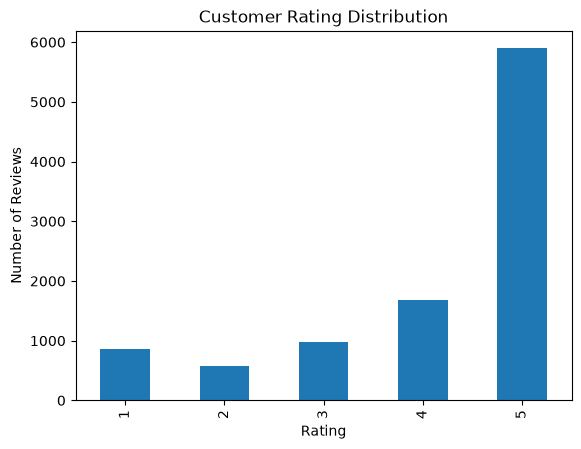

In [21]:
import matplotlib.pyplot as plt

df["rating"].value_counts().sort_index().plot(
    kind="bar",
    title="Customer Rating Distribution"
)

plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.show()